# Balancing a social accounting matrix

A social accounting matrix (SAM) records each flow in an economy once. Cell $(i, j)$ is a payment received by account $i$ from account $j$, so row $i$ sums to the income of account $i$ and column $i$ sums to its spending. In a balanced SAM, every account's income equals its spending.

A SAM assembled from national accounts, input-output tables, household surveys, and trade statistics does not balance, because each source measures its own block of the matrix with its own errors. Balancing starts from this unbalanced SAM, called the prior, and finds the closest SAM that satisfies the accounting identity and whatever else is known, such as published totals, precisely measured cells, tax rates, and caps on aggregates.

`cg.SymbolicSAM` turns the nonzero cells of the prior into symbols. Constraints are comparisons between linear expressions in those symbols, and `fit` solves for the closest balanced SAM with [cvxpy](https://www.cvxpy.org/).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import cge_modeling as cg

from cge_modeling.tools.sam_estimation import linear_constraints

## The prior

The example SAM has 15 accounts in five groups, with a two-level index on both axes. Empty cells are flows that do not exist and are read as zero. A negative entry is a flow in the opposite direction. The two negative cells here are in the capital account row: the savings of the government and of the rest of the world are both negative.

In [2]:
prior = pd.read_csv("../data/unbalanced_sam.csv",
                    index_col=[0, 1],
                    header=[0, 1]).fillna(0.0)
prior

Factor                                        \
                             Labor Unskilled Labor Skilled Labor Capital   
Factor      Labor              0.0             0.0           0.0     0.0   
            Unskilled Labor    0.0             0.0           0.0     0.0   
            Skilled Labor      0.0             0.0           0.0     0.0   
            Capital            0.0             0.0           0.0     0.0   
Institution Household        600.0          6070.0        1400.0  1200.0   
            Firm               0.0             0.0           0.0     0.0   
            Government         0.0             0.0           0.0     0.0   
Commodity   Agriculture        0.0             0.0           0.0     0.0   
            Industry           0.0             0.0           0.0     0.0   
            Service            0.0             0.0           0.0     0.0   
Activity    Agriculture        0.0             0.0           0.0     0.0   
            Industry           0.0             0.0           0.0     0.0   
            Service            0.0             0.0           0.0     0.0   
Other       Capital            0.0             0.0           0.0     0.0   
            Rest of World      0.0             0.0           0.0     0.0   

                            Institution                   Commodity           \
                              Household Firm Government Agriculture Industry   
Factor      Labor                   0.0  0.0        0.0         0.0      0.0   
            Unskilled Labor         0.0  0.0        0.0         0.0      0.0   
            Skilled Labor           0.0  0.0        0.0         0.0      0.0   
            Capital                 0.0  0.0        0.0         0.0      0.0   
Institution Household               0.0  0.0      100.0         0.0      0.0   
            Firm                    0.0  0.0        0.0         0.0      0.0   
            Government           1400.0  0.0        0.0       165.0   1365.0   
Commodity   Agriculture          1750.0  0.0      500.0         0.0      0.0   
            Industry             1200.0  0.0     1030.0         0.0      0.0   
            Service              3400.0  0.0     2785.0         0.0      0.0   
Activity    Agriculture             0.0  0.0        0.0      5500.0      0.0   
            Industry                0.0  0.0        0.0         0.0   9800.0   
            Service                 0.0  0.0        0.0         0.0      0.0   
Other       Capital              2180.0  0.0     -800.0         0.0      0.0   
            Rest of World           0.0  0.0        0.0       150.0    440.0   

                                        Activity                    Other  \
                             Service Agriculture Industry Service Capital   
Factor      Labor                0.0       690.0      0.0     0.0     0.0   
            Unskilled Labor      0.0       480.0   1530.0  4060.0     0.0   
            Skilled Labor        0.0       200.0    870.0   280.0     0.0   
            Capital              0.0        50.0    900.0   250.0     0.0   
Institution Household            0.0         0.0      0.0     0.0     0.0   
            Firm                 0.0         0.0      0.0     0.0     0.0   
            Government         280.0        50.0    140.0    90.0     0.0   
Commodity   Agriculture          0.0      1120.0    930.0  1150.0   200.0   
            Industry             0.0      2200.0   3120.0  3398.0   745.0   
            Service              0.0       870.0   2250.0  1100.0   100.0   
Activity    Agriculture          0.0         0.0      0.0     0.0     0.0   
            Industry             0.0         0.0      0.0     0.0     0.0   
            Service          10200.0         0.0      0.0     0.0     0.0   
Other       Capital              0.0         0.0      0.0     0.0     0.0   
            Rest of World       95.0         0.0      0.0     0.0     0.0   

                                           
                    

Income minus spending for each account shows how far the prior is from balance. The services commodity and the rest of the world carry most of the gap, with opposite signs.

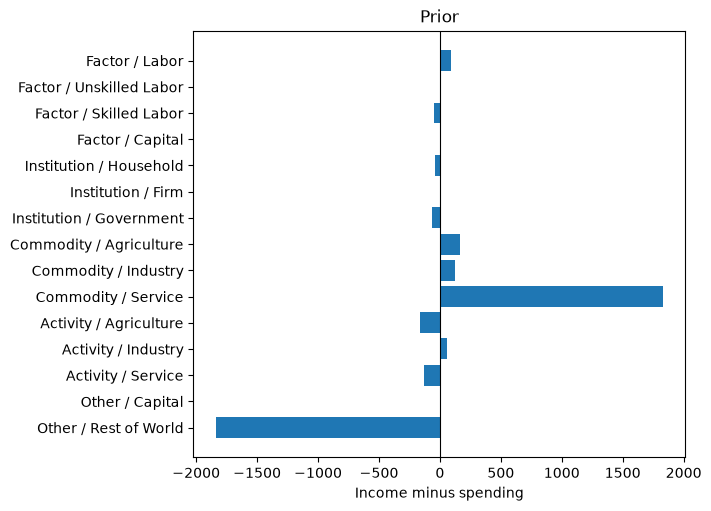

In [3]:
fig, ax = plt.subplots(figsize=(7, 5), layout="constrained")
imbalance = prior.sum(axis=1) - prior.sum(axis=0)
ax.barh(y=[" / ".join(label) for label in imbalance.index], width=imbalance.to_numpy())
ax.axvline(x=0.0,
           color="black",
           linewidth=0.8)
ax.invert_yaxis()
ax.set(title="Prior", xlabel="Income minus spending")
plt.show()

## The estimation problem

Let $z_k$ be the nonzero cells of the prior and $x_k$ the corresponding cells of the estimate. Cells that are zero in the prior stay zero, so the estimate keeps the prior's structure. `fit` solves

$$
\begin{aligned}
\min_x \quad & \sum_k |x_k| \log \frac{|x_k|}{|z_k|} - |x_k| + |z_k| \\
\text{subject to} \quad & \operatorname{sign}(x_k) = \operatorname{sign}(z_k) \\
& \sum_j x_{ij} = \sum_j x_{ji} \quad \text{for every account } i \\
& \sum_i \sum_j g^{(m)}_{ij} x_{ij} = c^{(m)} \quad m = 1, \dots, M \\
& \sum_i \sum_j h^{(l)}_{ij} x_{ij} \le e^{(l)} \quad l = 1, \dots, L
\end{aligned}
$$

The last two lines are aggregation constraints in the form of {cite:t}`robinson-cattaneo-el-said-2001`. The weights $g^{(m)}_{ij}$ are one on the cells of an aggregate and zero elsewhere, and $c^{(m)}$ is its known value, so a known row total, a fixed cell, or a national accounts aggregate is one equality each. Weights other than one express ratios, such as a tax rate applied to a tax base. The inequalities bound aggregates of the same kind, and a lower bound is an upper bound on the negated sum.

The objective is the generalized Kullback-Leibler divergence of the cell magnitudes from the prior magnitudes. It is zero exactly when the estimate equals the prior, so a SAM that already satisfies the constraints comes back unchanged. Applying it to magnitudes with fixed signs handles negative cells the way GRAS does {cite:p}`junius-oosterhaven-2003`. For nonnegative cells and the accounting identity alone, it is the problem RAS solves.

With only the accounting identity, the solution has a closed form up to one number per account {cite:p}`eaves-hoffman-rothblum-schneider-1985`. Each account $i$ has a scale $d_i$, and

$$
x_{ij} = \begin{cases} z_{ij} \, d_j / d_i & z_{ij} > 0 \\ z_{ij} \, d_i / d_j & z_{ij} < 0 \end{cases}
$$

A positive cell is divided by the scale of its row account and multiplied by the scale of its column account. A negative cell scales the other way, as a positive flow of the same size in the transposed cell would.

## Balancing with the identity alone

`fit` imposes the accounting identity on every call. It returns a `SAMEstimate` holding the balanced SAM, the objective value in the prior's units, and the solver status.

In [4]:
sam = cg.SymbolicSAM(prior)
estimate = sam.fit()

imbalance = estimate.sam.sum(axis=1) - estimate.sam.sum(axis=0)
pd.DataFrame({"accounts": [sam.n_accounts],
              "nonzero cells": [sam.n_cells],
              "status": [estimate.status],
              "objective": [estimate.objective],
              "largest imbalance": [imbalance.abs().max()]})

,accounts,nonzero cells,status,objective,largest imbalance
0,15,54,optimal,504.495551,1.818989e-12


The relative change in each cell shows where the adjustment went. Zero cells stay zero, and the two negative cells stay negative. In the prior the rest of the world receives far less than it pays, and its single scale $d_i$ closes that gap. Its receipts rise by 64 to 76% and its payments fall by about 40%, while its negative savings grow by about 60%, because negative cells scale the other way. Most other cells change by 10% or less.

In [5]:
def relative_change(estimate_sam, prior):
    return (estimate_sam / prior - 1.0).where(prior != 0.0)


def plot_relative_change(estimate_sam, prior, ax, title, limit):
    image = ax.imshow(relative_change(estimate_sam=estimate_sam, prior=prior).to_numpy(),
                      cmap="RdBu_r",
                      vmin=-limit,
                      vmax=limit)

    names = [" / ".join(label) for label in prior.index]
    ax.set_xticks(ticks=range(len(names)),
                  labels=names,
                  rotation=90)
    ax.set_yticks(ticks=range(len(names)), labels=names)
    ax.set(title=title,
           xlabel="Paying account (column)",
           ylabel="Receiving account (row)")
    return image

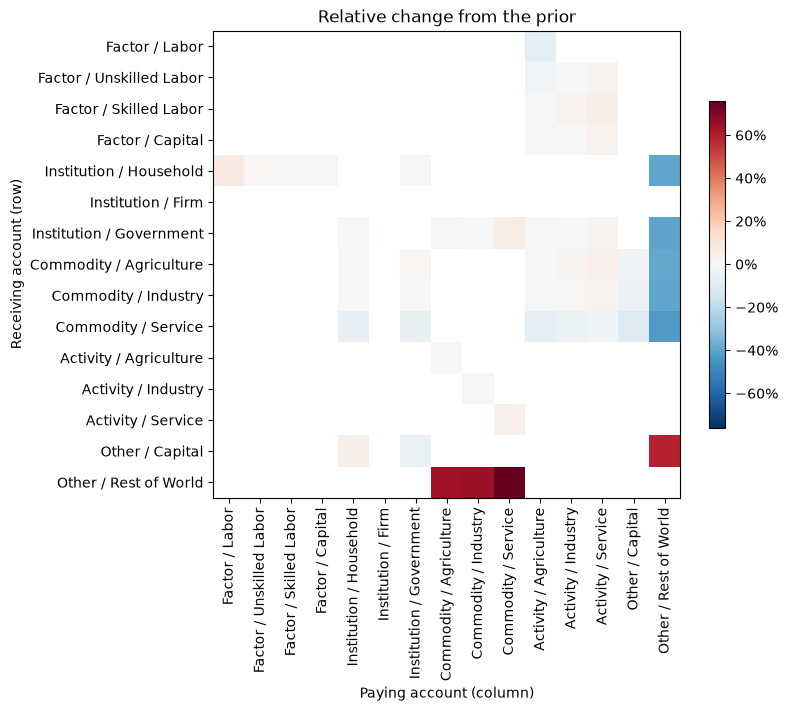

In [6]:
fig, ax = plt.subplots(figsize=(8, 7), layout="constrained")
limit = np.nanmax(np.abs(relative_change(estimate_sam=estimate.sam, prior=prior).to_numpy()))
image = plot_relative_change(estimate_sam=estimate.sam,
                             prior=prior,
                             ax=ax,
                             title="Relative change from the prior",
                             limit=limit)
fig.colorbar(image,
             ax=ax,
             shrink=0.7,
             format="{x:.0%}");

The closed form says $\log(x_{ij} / z_{ij}) = \pm(\log d_j - \log d_i)$ on every nonzero cell, with the sign of $z_{ij}$. Fitting one log scale per account to the log ratios by least squares recovers the scales, with a residual at rounding error, because `fit` solves for these scales directly when no constraints are added. The total of the SAM falls from 80107 to 79302.

In [7]:
log_ratio = np.log(estimate.sam.to_numpy()[sam.rows, sam.columns] / sam.prior_values)

cells = np.arange(sam.n_cells)
design = np.zeros((sam.n_cells, sam.n_accounts))
design[cells, sam.columns] += sam.signs
design[cells, sam.rows] -= sam.signs
log_scales, *_ = np.linalg.lstsq(a=design,
                                 b=log_ratio,
                                 rcond=None)

pd.DataFrame({"largest log residual": [np.abs(design @ log_scales - log_ratio).max()],
              "prior total": [prior.to_numpy().sum()],
              "balanced total": [estimate.sam.to_numpy().sum()]})

,largest log residual,prior total,balanced total
0,7.858297e-16,80107.0,79302.112323


## Constraints and Expressions 

Balancing with the identity alone uses no information beyond the prior. Additional infromation about the SAM can be introduced via constraints. Constraints are linear functions of the cells.

`sam.sel(row=..., col=...)` selects cells by label, and returns a `SAMExpression` object. A label can be a full account such as `("Institution", "Household")`, a first-level group such as `"Factor"` that selects every account under it, or a list of accounts. Selecting a single account drops that dim. The result carries the account labels of each remaining dim.

In [8]:
factor_payments = sam.sel(row="Factor", col=("Activity", "Industry"))
type(factor_payments), factor_payments.dims, factor_payments.labels["row"].tolist()

(cge_modeling.tools.sam_estimation.SAMExpression,
 ('row',),
 [('Factor', 'Labor'),
  ('Factor', 'Unskilled Labor'),
  ('Factor', 'Skilled Labor'),
  ('Factor', 'Capital')])

Expressions sum over a dim or over all of them, add and subtract with other expressions, numbers, or a `pandas.Series` aligned by label, and scale by numbers. Multiplying two expressions raises `TypeError`, so every constraint is linear in the cells. Comparing an expression with `==`, `<=` or `>=` gives a `Constraint`. Strict `<` and `>` raise, because the solver cannot impose them.

`sam.sum("col")` sums over columns and leaves one income total per account, on the `row` dim. `sam.sum("row")` gives spending on the `col` dim. Adding two expressions with different dims raises, because the result would be an outer product, so comparing income with spending account by account needs a rename. This is how `fit` writes the accounting identity.

Before solving, `fit` turns each constraint into rows of a sparse coefficient matrix over the nonzero cells, using the Jacobian of the pytensor graph behind the expression. `linear_constraints` exposes that step. The identity gives one row per account, and applying those rows to the prior cells reproduces the imbalance plotted above.

In [9]:
balance = sam.sum("col") == sam.sum("row").rename({"col": "row"})
compiled = linear_constraints(sam, [balance])

print(f"coefficient matrix shape: {compiled.equality_operator.shape}")
pd.DataFrame(data={"prior imbalance": compiled.equality_operator @ sam.prior_values},
             index=prior.index).round(1)

coefficient matrix shape: (15, 54)


prior imbalance
Factor      Labor                       90.0
            Unskilled Labor              0.0
            Skilled Labor              -50.0
            Capital                      0.0
Institution Household                  -37.0
            Firm                         0.0
            Government                 -67.0
Commodity   Agriculture                166.0
            Industry                   125.0
            Service                   1830.0
Activity    Agriculture               -160.0
            Industry                    60.0
            Service                   -128.0
Other       Capital                     10.0
            Rest of World            -1839.0

## Adding what is known

`subject_to` takes constraints as keyword arguments, and the keyword names each one. Suppose the following are known from sources more reliable than the rest of the prior:

- Household income is 9893, the figure from the household survey.
- Gross output of agriculture and industry is known from the production census. Service output is not, so its entry in the Series is NaN, and NaN entries impose nothing.
- Labor income in agriculture is 690, measured directly.
- Imports of commodities from the rest of the world are at most 900.
- Production taxes are 3% of factor payments by activities, a statutory rate.

In [10]:
household = ("Institution", "Household")
government = ("Institution", "Government")
rest_of_world = ("Other", "Rest of World")

census_totals = pd.Series(data=[5500.0, 9800.0, np.nan],
                          index=pd.MultiIndex.from_tuples([("Activity", "Agriculture"),
                                                           ("Activity", "Industry"),
                                                           ("Activity", "Service")]))

constrained = cg.SymbolicSAM(prior)

household_income = constrained.sel(row=household).sum() == 9893.0
census_output = constrained.sum("col") == census_totals
agricultural_wages = constrained.sel(row=("Factor", "Labor"), col=("Activity", "Agriculture")) == 690.0
import_cap = constrained.sel(row=rest_of_world, col="Commodity").sum() <= 900.0
production_tax = (constrained.sel(row=government, col="Activity").sum()
                  == 0.03 * constrained.sel(row="Factor", col="Activity").sum())

constrained.subject_to(household_income=household_income,
                       census_output=census_output,
                       agricultural_wages=agricultural_wages,
                       import_cap=import_cap,
                       production_tax=production_tax)

list(constrained.constraints)

['household_income',
 'census_output',
 'agricultural_wages',
 'import_cap',
 'production_tax']

In [11]:
def known_quantities(sam_frame):
    factor_payments_by_activities = sam_frame.loc["Factor", "Activity"].to_numpy().sum()
    return pd.Series({"household income": sam_frame.loc[household].sum(),
                      "agriculture output": sam_frame.loc[("Activity", "Agriculture")].sum(),
                      "industry output": sam_frame.loc[("Activity", "Industry")].sum(),
                      "agricultural wages": sam_frame.loc[("Factor", "Labor"), ("Activity", "Agriculture")],
                      "imports": sam_frame.loc[rest_of_world, "Commodity"].sum(),
                      "production tax rate": sam_frame.loc[government, "Activity"].sum() / factor_payments_by_activities})


constrained_estimate = constrained.fit()
balanced = constrained_estimate.sam

print(f"status: {constrained_estimate.status}, objective: {constrained_estimate.objective:.2f}")
pd.DataFrame({"prior": known_quantities(prior),
              "identity only": known_quantities(estimate.sam),
              "with known data": known_quantities(balanced)}).round(3)

status: optimal, objective: 552.39


,prior,identity only,with known data
household income,9893.00,9798.563,9893.00
agriculture output,5500.00,5512.459,5500.00
industry output,9800.00,9704.283,9800.00
agricultural wages,690.00,640.984,690.00
imports,685.00,1141.419,900.00
production tax rate,0.03,0.030,0.03


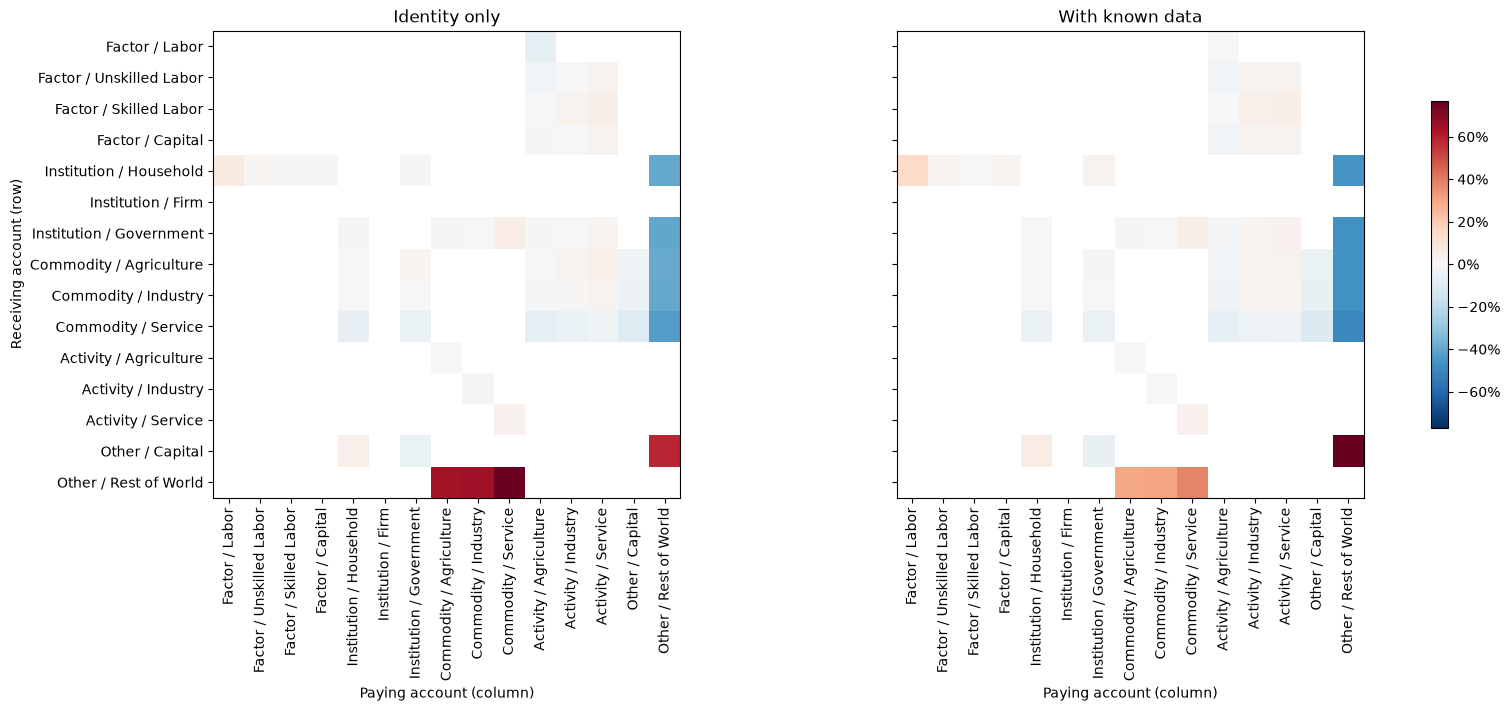

In [12]:
limit = max(np.nanmax(np.abs(relative_change(estimate_sam=estimate.sam, prior=prior).to_numpy())),
            np.nanmax(np.abs(relative_change(estimate_sam=balanced, prior=prior).to_numpy())))

fig, axes = plt.subplots(ncols=2,
                         figsize=(15, 7),
                         layout="constrained",
                         sharey=True)
plot_relative_change(estimate_sam=estimate.sam,
                     prior=prior,
                     ax=axes[0],
                     title="Identity only",
                     limit=limit)
image = plot_relative_change(estimate_sam=balanced,
                             prior=prior,
                             ax=axes[1],
                             title="With known data",
                             limit=limit)
axes[1].set_ylabel("")
fig.colorbar(image,
             ax=axes,
             shrink=0.7,
             format="{x:.0%}");

The import cap binds at 900, so imports rise by 30 to 38% where the identity alone raised them by 64 to 76%. The rest of the world still has to balance, so its other cells absorb more of the gap: its payments to households, the government, and commodities fall by 45 to 49% instead of about 40%, and its negative savings grow from 325 to 575, against 514 with the identity alone. Household income, census output, and agricultural wages hold at their known values, where the identity alone moved household income to 9798 and agricultural wages to 641.

The objective rises from 504.50 to 552.39, because the constraints hold the estimate further from the prior.

## When balancing cannot work

Balancing can only rescale flows that lie on a closed loop of payments. Draw an edge from account $j$ to account $i$ for every positive cell $(i, j)$, and the reverse edge for every negative one. A cell whose edge lies on no directed cycle of that graph can only be balanced by setting it to zero. `fit` checks for such cells before solving and raises an error that lists them, because setting them to zero silently would delete data. In the SAM below, account `c` receives a payment from `a` but pays nothing, so balancing `c` would force that payment to zero.

In [13]:
dead_end = pd.DataFrame(data=[[0.0, 2.0, 0.0], [3.0, 0.0, 0.0], [1.0, 0.0, 0.0]],
                        index=list("abc"),
                        columns=list("abc"))

try:
    cg.SymbolicSAM(dead_end).fit()
except ValueError as error:
    print(error)

Balancing sets these cells to zero, because they lie on no cycle of the account graph: [('c', 'a')]. Remove them from the prior or add the missing flows.


Constraints that contradict each other have no solution, and `fit` raises an error with the solver status. A constraint that involves only cells that are zero in the prior, which stay zero, raises before the solve and names the constraint.

Here the constraints fix the income of `a` at 5 and its spending at 7, which the identity forbids.

In [14]:
two_accounts = cg.SymbolicSAM(pd.DataFrame(data=[[0.0, 2.0], [1.0, 0.0]],
                                           index=["a", "b"],
                                           columns=["a", "b"]))
two_accounts.subject_to(income=two_accounts.sel(row="a").sum() == 5.0,
                        spending=two_accounts.sel(col="a").sum() == 7.0)

try:
    two_accounts.fit()
except ValueError as error:
    print(error)

The SAM estimate has no solution: solver status is 'infeasible'. The constraints contradict each other or the accounting identity


## Solver accuracy

`fit` picks a solver unless one is named. With no constraints beyond the accounting identity, it uses the `"dual"` solver, which solves the balance equations for the account scales $d_i$ of the closed form by Newton's method on their sparse Jacobian, a graph Laplacian, with `sparse_root` from `cge_modeling.solvers`. It is optimal when every account balances to $10^{-12}$ of its turnover. Each cell's error is then proportional to the cell, so even the smallest cells come out accurate.

Any added constraint sends the problem to cvxpy, with the CLARABEL solver by default. Before solving, `fit` divides every cell by the total of the absolute cell values, and CLARABEL's tolerances apply to that scaled problem. Its error is therefore roughly the same in absolute terms for every cell and grows with the total of the SAM. Large cells come out accurate to a small relative error, but a cell not much larger than that absolute error can come out wrong by a large factor. Keyword arguments to `fit` pass through to whichever solver runs, `sparse_root` or `cvxpy.Problem.solve`, so tighter tolerances reduce the error.

Solving the identity-only problem with CLARABEL and comparing it with the dual solution measures CLARABEL's error. On this SAM the largest error is about 0.1 against a smallest cell of 37, so every cell is accurate to better than $10^{-3}$ relative.

In [15]:
clarabel = sam.fit(solver="CLARABEL")
cell_error = (clarabel.sam - estimate.sam).abs()
relative_error = (cell_error / estimate.sam.abs()).where(prior != 0.0)

pd.DataFrame({"total of absolute cells": [np.abs(prior.to_numpy()).sum()],
              "smallest cell": [np.abs(sam.prior_values).min()],
              "largest absolute error": [cell_error.to_numpy().max()],
              "largest relative error": [np.nanmax(relative_error.to_numpy())]})

,total of absolute cells,smallest cell,largest absolute error,largest relative error
0,82357.0,37.0,0.107301,0.000453


## References

```{bibliography}
```

## Authors

- Created by Jesse Grabowski, November 21, 2026

## Watermark

In [16]:
%load_ext watermark
%watermark -n -u -v -iv -m -w

Last updated: Wed, 25 Nov 2026

Python implementation: CPython
Python version       : 3.12.13
IPython version      : 9.18.1

Compiler    : Clang 19.1.7 
OS          : Darwin
Release     : 25.6.0
Machine     : arm64
Processor   : arm
CPU cores   : 14
Architecture: 64bit

cge_modeling: 0.0.7.dev15+g93cb61e4e.d20261120
matplotlib  : 3.11.2
numpy       : 2.3.5
pandas      : 3.1.1

Watermark: 2.6.0

